# Space Fog: predicting cognitive-decline risk in astronauts

This notebook builds the models behind the Space Fog app, combines them into crew recommendations, and exports them to the app.

| Section | Parts | Data | Output |
|---|---|---|---|
| A. Wearable physiology | 1–5 | PhysioNet respiratory & heart-rate dataset (ECG, PPG, airway pressure) | `space_fog_phys_model.joblib`: physiological strain classifier |
| B. Risk fusion & recommendations | 6–7 | Section A + cognitive test scores + sleep | Space Fog risk score (0–1) and task actions |
| C. ISS cabin environment | 8–10 | NASA OSDR Environmental Data Application (EDA) API, mission RR-1 | 6-hour forecast of CO₂, temperature and humidity |
| D. ISS radiation | 11 | NASA OSDR RadLab API, DOSIS-3D DOSTEL-1 dosimeter | Dose-rate map of the orbit and a 24-hour dose forecast |
| E. Link to the app | 12 | Sections A, C and D | `space_fog_models.json`: the trained models, read by the Space Fog app |

Run the cells top to bottom. Each part starts with a short note on what it does and why.

# Section A: Wearable physiology

## Part 1: Dataset setup & verification
We use the PhysioNet *respiratory-heartrate-dataset* (20 subjects × 3 breathing maneuvers = 60 recordings). The cell below downloads it once into `/content` and skips the download if the files are already there, so re-running is safe.

**What changed here:** the original notebook downloaded the same files three times (two `wget` cells and this one). Only this cell is kept: it is the only one that checks for existing files and fails loudly if a download fails.

In [1]:
import pandas as pd

In [2]:
import os
import subprocess

%cd /content

if not os.path.exists("/content/Processed_Dataset"):
    print("Downloading Processed_Dataset from PhysioNet...")
    subprocess.run([
        "wget", "-q", "-r", "-np", "-nH", "--cut-dirs=3", "-R", "index.html*",
        "https://physionet.org/files/respiratory-heartrate-dataset/1.0.0/Processed_Dataset/"
    ], check=True)

if not os.path.exists("/content/subject-info.csv"):
    subprocess.run([
        "wget", "-q",
        "https://physionet.org/files/respiratory-heartrate-dataset/1.0.0/subject-info.csv"
    ], check=True)

print("Files ready:", len(os.listdir("/content/Processed_Dataset")))

/content
Files ready: 60


## Part 2: Multimodal signal alignment
Each recording has three sensors sampled on **different clocks**: airway pressure/flow (PSD), ECG and PPG. To analyze them together we:

1. Split each file into one table per sensor, sorted by its own timestamps, with duplicate timestamps removed.
2. Keep only the time window where **all three sensors overlap**.
3. Resample every signal onto one common grid at **250 Hz** (one sample every 4 ms) with linear interpolation. The breath-index column is discrete, so it uses nearest-neighbor instead, to avoid inventing fractional indices.
4. Stack all 60 trials, attach subject demographics, and save to Parquet so later parts can reload it quickly.

In [3]:
import glob
import os
import re
import numpy as np
import pandas as pd

DATA_DIR = "/content/Processed_Dataset"
SUBJECT_INFO_PATH = "/content/subject-info.csv"
TARGET_FS = 250.0  # Common resampling frequency in Hz (dt = 0.004 s)


def extract_modality(df: pd.DataFrame, time_col: str, value_cols: list[str]) -> pd.DataFrame:
    """Extracts a clean, sorted, duplicate-free block for a single sensor modality."""
    sub = df[[time_col] + value_cols].dropna(subset=[time_col]).copy()
    sub = sub.sort_values(time_col).drop_duplicates(subset=[time_col])
    return sub


def align_single_trial(filepath: str, target_fs: float = 250.0) -> pd.DataFrame:
    """Aligns PSD, ECG, and PPG from one CSV onto a uniform time grid."""
    filename = os.path.basename(filepath)
    match = re.match(r"ProcessedData_Subject(\d+)_(PEEP_BH|PEEP|FEM)\.csv", filename)
    if not match:
        raise ValueError(f"Unexpected filename format: {filename}")

    subject_id = int(match.group(1))
    test_type = match.group(2)

    df = pd.read_csv(filepath)

    # 1. Separate each modality with its native time array
    psd_cols = [
        "PSD Gauge Pressure [cmH2O]",
        "PSD Inspiratory Differential Pressure [cmH2O]",
        "PSD Expiratory Differential Pressure [cmH2O]",
        "PSD Flow [L/s]",
        "PSD Tidal Volume [L]",
        "PSD Inspiratory Indicies",
    ]
    ecg_cols = ["ECG [mV]"]
    ppg_cols = ["PPG0", "PPG1", "PPG2"]

    psd = extract_modality(df, "PSD Time [s]", psd_cols)
    ecg = extract_modality(df, "ECG Time [s]", ecg_cols)
    ppg = extract_modality(df, "PPG Time [s]", ppg_cols)

    # 2. Define overlapping time window across all three sensors
    t_start = max(psd["PSD Time [s]"].min(), ecg["ECG Time [s]"].min(), ppg["PPG Time [s]"].min())
    t_end = min(psd["PSD Time [s]"].max(), ecg["ECG Time [s]"].max(), ppg["PPG Time [s]"].max())
    common_time = np.arange(t_start, t_end, 1.0 / target_fs)

    aligned = pd.DataFrame({
        "subject_id": subject_id,
        "test_type": test_type,
        "time_s": common_time,
    })

    # 3. Linear interpolation onto common_time
    for col in psd_cols:
        if col == "PSD Inspiratory Indicies":
            # Use nearest-neighbor for discrete event indices
            idx = np.searchsorted(psd["PSD Time [s]"].values, common_time, side="left")
            idx = np.clip(idx, 0, len(psd) - 1)
            aligned[col] = psd[col].values[idx]
        else:
            aligned[col] = np.interp(common_time, psd["PSD Time [s]"].values, psd[col].values)

    for col in ecg_cols:
        aligned[col] = np.interp(common_time, ecg["ECG Time [s]"].values, ecg[col].values)

    for col in ppg_cols:
        aligned[col] = np.interp(common_time, ppg["PPG Time [s]"].values, ppg[col].values)

    return aligned


# Merge all 60 files
csv_files = sorted(glob.glob(os.path.join(DATA_DIR, "ProcessedData_Subject*.csv")))
all_trials = [align_single_trial(f, target_fs=TARGET_FS) for f in csv_files]
merged_df = pd.concat(all_trials, ignore_index=True)

# Attach subject demographics if available
if os.path.exists(SUBJECT_INFO_PATH):
    info = pd.read_csv(SUBJECT_INFO_PATH)
    id_col = info.columns[0]
    merged_df = merged_df.merge(info, left_on="subject_id", right_on=id_col, how="left")

# Save in Parquet format in a guaranteed absolute local path
merged_df.to_parquet("/content/merged_ecg_psd_ppg.parquet", index=False)
print(f"Merged shape: {merged_df.shape}")

Merged shape: (3771528, 40)


## Part 3: Feature extraction
First, a visual check: plot 15 seconds of one subject to confirm the aligned signals look physiological (regular ECG beats, PPG pulses following them).

Then we cut every trial into **non-overlapping 15-second windows** and compute one row of features per window:

| Feature | From | Meaning |
|---|---|---|
| `hr_bpm` | ECG R-peaks | Heart rate |
| `rmssd_ms` | ECG R-R intervals | Heart-rate variability (falls under stress) |
| `pat_ms` | ECG → PPG peak delay | Pulse arrival time (tracks blood-pressure changes) |
| `ppg_amp` | PPG | Pulse amplitude (drops with vasoconstriction) |
| pressure / flow / tidal volume | PSD | Breathing context (used to find resting windows) |

Windows are non-overlapping so neighboring rows are not near-copies of each other.

**Fix applied (heart-rate artifacts):** the earlier output showed RMSSD = 708 ms in one window, which is not physiological (resting RMSSD is usually 20–100 ms). It comes from a missed or extra R-peak. Beats outside 30–200 bpm and jumps of more than 20 % between consecutive beats are now excluded before computing heart rate and RMSSD. This is the standard HRV cleaning rule; without it, artifacts were being labeled as "strain". Windows with too few R-peaks or a signal-processing error (usually motion artifacts during forced expiration) are skipped.

Columns: ['subject_id', 'test_type', 'time_s', 'PSD Gauge Pressure [cmH2O]', 'PSD Inspiratory Differential Pressure [cmH2O]', 'PSD Expiratory Differential Pressure [cmH2O]', 'PSD Flow [L/s]', 'PSD Tidal Volume [L]', 'PSD Inspiratory Indicies', 'ECG [mV]', 'PPG0', 'PPG1', 'PPG2', 'Subject Number', 'Sex (M/F)', 'Height [cm]', 'Weight [kg]', 'Age [years]', 'Bra Size (if applicable)', 'Back Size', 'Sternum to spine size', 'Asthma (Y/N)', 'Medication', 'Dosage Frequency', 'History of Smoking (Y/N)', 'Current Smoker (Y/N)', 'How long since you quit smoking', 'Smoking Frequency', 'Time as a smoker ', 'History of Vaping (Y/N)', 'Current Vaper (Y/N)', 'How long since you quit vaping', 'Vaping Frequency', 'Time as a vaper', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']


Total NaNs in core signals: {'PSD Flow [L/s]': 0, 'ECG [mV]': 0, 'PPG0': 0}


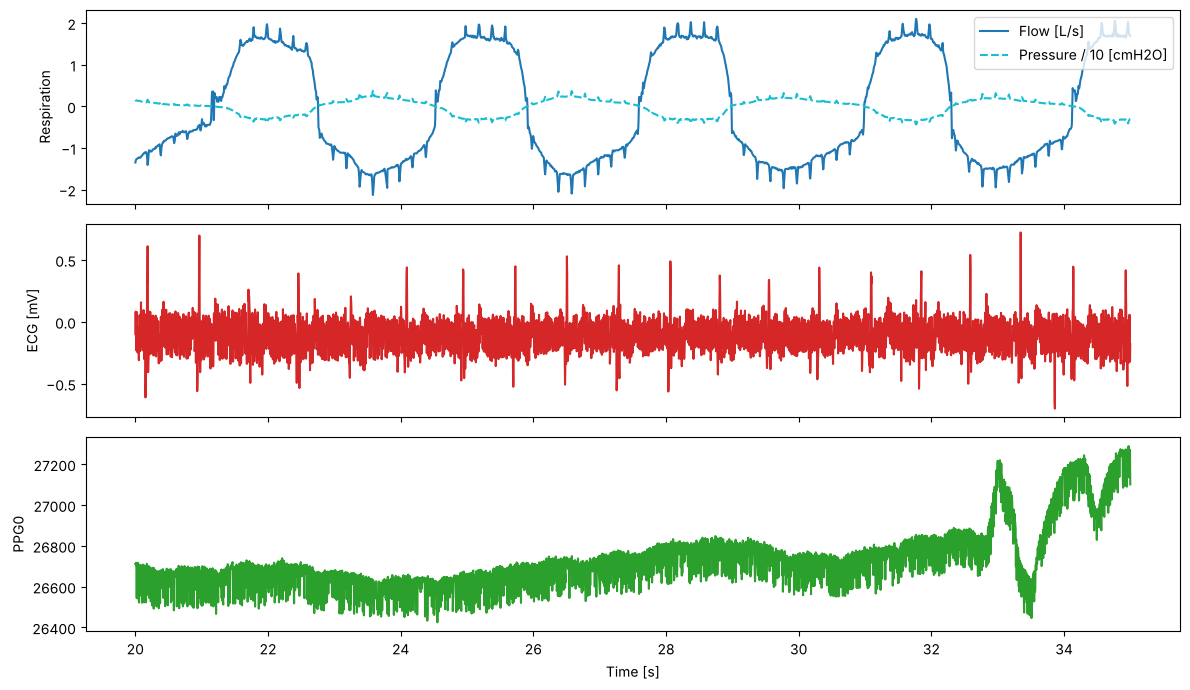

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load if starting a fresh session; otherwise merged_df is already in memory
df = pd.read_parquet("merged_ecg_psd_ppg.parquet")

print("Columns:", list(df.columns))
print("Total NaNs in core signals:", df[["PSD Flow [L/s]", "ECG [mV]", "PPG0"]].isna().sum().to_dict())

# Plot a 15-second slice from Subject 1 during PEEP
sub = df[(df["subject_id"] == 1) & (df["test_type"] == "PEEP")]
win = sub[(sub["time_s"] >= 20) & (sub["time_s"] <= 35)]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(win["time_s"], win["PSD Flow [L/s]"], color="tab:blue", label="Flow [L/s]")
axes[0].plot(win["time_s"], win["PSD Gauge Pressure [cmH2O]"] / 10, color="tab:cyan", linestyle="--", label="Pressure / 10 [cmH2O]")
axes[0].set_ylabel("Respiration")
axes[0].legend(loc="upper right")

axes[1].plot(win["time_s"], win["ECG [mV]"], color="tab:red")
axes[1].set_ylabel("ECG [mV]")

axes[2].plot(win["time_s"], win["PPG0"], color="tab:green")
axes[2].set_ylabel("PPG0")
axes[2].set_xlabel("Time [s]")

plt.tight_layout()
plt.show()

In [5]:
!pip install -q neurokit2

In [6]:
import numpy as np
import pandas as pd
import neurokit2 as nk
import os

FS = 250
WIN_SEC = 15
WIN_SAMPLES = FS * WIN_SEC

# Read from the guaranteed local path
physio_df = pd.read_parquet("/content/merged_ecg_psd_ppg.parquet")

feature_rows = []

for (subj_id, test_type), trial in physio_df.groupby(["subject_id", "test_type"]):
    trial = trial.sort_values("time_s").reset_index(drop=True)

    # Slide across the trial in non-overlapping 15-second windows
    for start in range(0, len(trial) - WIN_SAMPLES, WIN_SAMPLES):
        w = trial.iloc[start : start + WIN_SAMPLES]

        try:
            # 1. PSD (Respiratory) features
            mean_peep = w["PSD Gauge Pressure [cmH2O]"].mean()
            flow_ptp = w["PSD Flow [L/s]"].max() - w["PSD Flow [L/s]"].min()
            tidal_vol_range = w["PSD Tidal Volume [L]"].max() - w["PSD Tidal Volume [L]"].min()

            # 2. ECG features (R-peaks, Heart Rate, RMSSD)
            ecg_clean = nk.ecg_clean(w["ECG [mV]"].values, sampling_rate=FS)
            _, rpeaks_dict = nk.ecg_peaks(ecg_clean, sampling_rate=FS)
            r_peaks = rpeaks_dict["ECG_R_Peaks"]

            if len(r_peaks) < 5:
                continue

            rr_ms = np.diff(r_peaks) / FS * 1000.0

            # Artifact filter: keep beats at 30-200 bpm (300-2000 ms) and successive
            # differences only between two valid beats that change by <= 20 %
            # (standard ectopic/missed-beat rule). Without it, one missed R-peak
            # produces RMSSD values in the hundreds of ms.
            valid = (rr_ms >= 300) & (rr_ms <= 2000)
            d_rr = np.diff(rr_ms)
            d_ok = valid[1:] & valid[:-1] & (np.abs(d_rr) <= 0.2 * rr_ms[:-1])
            if valid.sum() < 4 or d_ok.sum() < 3:
                continue

            hr_bpm = 60000.0 / np.mean(rr_ms[valid])
            rmssd_ms = np.sqrt(np.mean(d_rr[d_ok] ** 2))

            # 3. PPG features & Pulse Arrival Time (PAT)
            ppg_clean = nk.ppg_clean(w["PPG0"].values, sampling_rate=FS)
            _, ppg_dict = nk.ppg_peaks(ppg_clean, sampling_rate=FS)
            p_peaks = ppg_dict["PPG_Peaks"]

            # Match each ECG R-peak to the next PPG systolic peak within 100-500 ms
            pats_ms = []
            for r in r_peaks:
                valid_p = p_peaks[(p_peaks > r + int(0.10 * FS)) & (p_peaks < r + int(0.50 * FS))]
                if len(valid_p) > 0:
                    pats_ms.append((valid_p[0] - r) / FS * 1000.0)

            median_pat_ms = np.median(pats_ms) if len(pats_ms) >= 3 else np.nan
            ppg_amp = np.percentile(ppg_clean, 95) - np.percentile(ppg_clean, 5)

            feature_rows.append({
                "subject_id": subj_id,
                "test_type": test_type,
                "win_start_s": w["time_s"].iloc[0],
                "mean_pressure_cmH2O": mean_peep,
                "flow_range_Ls": flow_ptp,
                "tidal_vol_range_L": tidal_vol_range,
                "hr_bpm": hr_bpm,
                "rmssd_ms": rmssd_ms,
                "pat_ms": median_pat_ms,
                "ppg_amp": ppg_amp,
            })
        except Exception:
            # Skip windows with severe motion artifacts (common during forced expiration)
            continue

features_df = pd.DataFrame(feature_rows)
features_df.to_csv("extracted_multimodal_features.csv", index=False)
print("Extracted feature table shape:", features_df.shape)
features_df.head()

Extracted feature table shape: (939, 10)


,subject_id,test_type,win_start_s,mean_pressure_cmH2O,flow_range_Ls,tidal_vol_range_L,hr_bpm,rmssd_ms,pat_ms,ppg_amp
0,1,FEM,0.000943,-0.177720,6.934376,9.499062,80.190080,38.292988,244.0,91.031909
1,1,FEM,15.000943,-1.077144,6.928258,9.498976,82.787168,69.558608,192.0,136.917135
2,1,FEM,30.000943,0.796427,6.506687,7.742517,90.465250,45.398238,186.0,176.909188
3,1,PEEP,0.000943,-0.263921,4.585946,4.089978,76.617480,32.219833,448.0,78.863620
4,1,PEEP,15.000943,-0.188778,4.187023,2.389951,77.675489,29.791432,416.0,73.117156


## Part 4: Personal baseline & z-score labeling
People differ a lot at rest (a resting heart rate of 55 or 80 can both be normal), so every feature is compared with **that person's own baseline**, not a population average:

1. **Baseline:** each subject's calmest windows (the 20 % with the lowest airway pressure during the PEEP maneuver, at least 3 windows) give a personal mean and SD. SD floors stop tiny resting variation from inflating z-scores.
2. **Z-scores:** distance from baseline in SDs. Heart rate counts only when it rises and PPG amplitude only when it falls; RMSSD and PAT count in either direction.
3. **Label:** a window is *abnormal* if the average z (`z_composite`) ≥ 1.5 or any single z ≥ 2.5.
4. **Strain score:** a smooth 0–1 version of `z_composite` (0.50 exactly at 1.5 SD), used later in Part 6.

Sanity check in the output: the hardest maneuver (FEM, forced expiration) should have the highest abnormal rate, and resting PEEP the lowest.

In [7]:
import numpy as np
import pandas as pd

features_df = pd.read_csv("extracted_multimodal_features.csv")

# Minimum SD floors prevent division-by-near-zero on very stable resting baselines
SD_FLOORS = {
    "hr_bpm": 2.0,
    "rmssd_ms": 3.0,
    "pat_ms": 5.0,
    "ppg_amp": 0.02,
}

def compute_subject_baselines(df: pd.DataFrame) -> pd.DataFrame:
    """Extracts personal resting mean & SD from each subject's lowest-pressure PEEP windows."""
    baselines = []
    for subj_id, grp in df.groupby("subject_id"):
        peep_grp = grp[grp["test_type"] == "PEEP"]
        # Fallback to all trials if PEEP is missing for a subject
        ref = peep_grp if len(peep_grp) >= 5 else grp

        # Take the lowest 20% airway-pressure windows (at least 3 windows) as resting baseline
        n_base = max(3, int(np.ceil(0.20 * len(ref))))
        base_win = ref.nsmallest(n_base, "mean_pressure_cmH2O")

        row = {"subject_id": subj_id}
        for col, floor in SD_FLOORS.items():
            row[f"{col}_mu"] = base_win[col].mean()
            raw_sd = base_win[col].std()
            row[f"{col}_sd"] = max(raw_sd, floor) if pd.notna(raw_sd) else floor
        baselines.append(row)

    return pd.DataFrame(baselines)

# 1. Merge personal baselines onto every window
baseline_df = compute_subject_baselines(features_df)
df = features_df.merge(baseline_df, on="subject_id", how="left")

# 2. Compute directional / perturbation Z-scores relative to personal baseline
df["z_hr"] = np.maximum(0.0, (df["hr_bpm"] - df["hr_bpm_mu"]) / df["hr_bpm_sd"])
df["z_rmssd"] = np.abs(df["rmssd_ms"] - df["rmssd_ms_mu"]) / df["rmssd_ms_sd"]
df["z_pat"] = np.abs(df["pat_ms"] - df["pat_ms_mu"]) / df["pat_ms_sd"]
df["z_ppg"] = np.maximum(0.0, (df["ppg_amp_mu"] - df["ppg_amp"]) / df["ppg_amp_sd"])

# Composite physiological deviation across available sensors
z_cols = ["z_hr", "z_rmssd", "z_pat", "z_ppg"]
df["z_composite"] = df[z_cols].mean(axis=1, skipna=True)
df["z_max"] = df[z_cols].max(axis=1, skipna=True)

# 3. Assign binary label (0 = Normal, 1 = Abnormal)
# Flagged if composite deviation >= 1.5 SD or any single biomarker spikes >= 2.5 SD
df["is_abnormal"] = ((df["z_composite"] >= 1.5) | (df["z_max"] >= 2.5)).astype(int)

# 4. Map to a smooth [0, 1] Physiological Strain Score (0.50 at the 1.5 SD threshold)
df["phys_strain_score"] = 1.0 / (1.0 + np.exp(-2.0 * (df["z_composite"] - 1.5)))

# Verify abnormal rate across maneuver types
print(df.groupby("test_type")[["is_abnormal", "phys_strain_score", "z_composite"]].mean())

df.to_csv("labeled_multimodal_features.csv", index=False)

           is_abnormal  phys_strain_score  z_composite
test_type                                             
FEM           0.796296           0.703267     3.485055
PEEP          0.246696           0.278218     1.189519
PEEP_BH       0.614849           0.513371     2.891374



## Part 5: Machine-learning model

### What Part 5 does and does not show
**The label is not independent of the inputs.** In Part 4, a window is labeled abnormal when the mean of its four z-scores is ≥ 1.5 or any one is ≥ 2.5. That threshold follows NASA's ±1.5 SD convention for a meaningful deviation (Dev et al. 2024 use z ≤ −1.5 for a low cognitive score; applying it to heart signals is our adaptation). The Random Forest is then trained on **those same four z-scores**.

So the cross-validated ROC-AUC (~0.999) measures how well the model **reproduces the labeling rule**. It is not evidence that the model detects real physiological strain, and it should not be presented as accuracy.

**How we test it honestly:** the cell after the model uses a label the model never saw, the **breathing maneuver**. Forced expiration (FEM) is a real physical stressor; resting PEEP is not. If the strain score is meaningful, it should separate FEM from resting PEEP windows. The personal-baseline windows are excluded from that test, because they are low by construction. We also report how the rule alone (`z_composite`) does, to show whether the forest adds anything beyond the rule.

### Evaluation set-up
- **Subject-independent cross-validation (`GroupKFold` by `subject_id`):** no person is in both training and validation, so scores reflect a **new person**.
- **Out-of-fold predictions:** every window is scored by a model that never trained on its subject.
- The final model is refit on all subjects and saved for the app's backend. `n_jobs=-1` only uses all CPU cores; results are identical.


In [8]:
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import GroupKFold

df = pd.read_csv("labeled_multimodal_features.csv").dropna(
    subset=["z_hr", "z_rmssd", "z_pat", "z_ppg", "is_abnormal"]
)

feature_cols = ["z_hr", "z_rmssd", "z_pat", "z_ppg"]
X = df[feature_cols]
y = df["is_abnormal"]
groups = df["subject_id"]

# Subject-independent 5-fold cross-validation
gkf = GroupKFold(n_splits=5)
oof_probs = np.zeros(len(df))

for train_idx, val_idx in gkf.split(X, y, groups):
    clf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
    clf.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_probs[val_idx] = clf.predict_proba(X.iloc[val_idx])[:, 1]

print(f"Rule-reproduction ROC-AUC (unseen subjects): {roc_auc_score(y, oof_probs):.3f}  <- agreement with the Part 4 rule, not strain-detection accuracy")
print(classification_report(y, (oof_probs >= 0.5).astype(int), target_names=["Normal", "Abnormal"]))

# Fit final model on all 20 subjects and save for your Space Fog backend
final_model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
final_model.fit(X, y)
joblib.dump({"model": final_model, "features": feature_cols}, "space_fog_phys_model.joblib")

Rule-reproduction ROC-AUC (unseen subjects): 0.999  <- agreement with the Part 4 rule, not strain-detection accuracy
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.99       274
    Abnormal       0.99      0.99      0.99       340

    accuracy                           0.99       614
   macro avg       0.99      0.99      0.99       614
weighted avg       0.99      0.99      0.99       614



['space_fog_phys_model.joblib']

### Independent validation: does the strain score track a real stressor?
Uses the out-of-fold probabilities from above (each from a model that never saw that subject) and compares FEM windows with resting PEEP windows. The maneuver label was never used to build the features or the label, so this ROC-AUC is the number to report.

In [9]:
# Maneuver type is independent of the model: it was never a feature or part of the label.
val = df.assign(oof_prob=oof_probs)

# Exclude the personal-baseline windows (same rule as Part 4): their z-scores are low by construction.
all_windows = pd.read_csv("labeled_multimodal_features.csv")
baseline_idx = []
for _, grp in all_windows.groupby("subject_id"):
    peep = grp[grp["test_type"] == "PEEP"]
    ref = peep if len(peep) >= 5 else grp
    n_base = max(3, int(np.ceil(0.20 * len(ref))))
    baseline_idx += ref.nsmallest(n_base, "mean_pressure_cmH2O").index.tolist()
val = val.drop(index=baseline_idx, errors="ignore")

print("Mean predicted strain probability by maneuver (baseline windows excluded):")
print(val.groupby("test_type")["oof_prob"].agg(["mean", "count"]).round(3))

pair = val[val["test_type"].isin(["FEM", "PEEP"])]
y_maneuver = (pair["test_type"] == "FEM").astype(int)
print("\nIndependent check, FEM (stress) vs PEEP (rest), unseen subjects:")
print(f"  Random Forest probability ROC-AUC: {roc_auc_score(y_maneuver, pair['oof_prob']):.3f}")
print(f"  Rule alone (z_composite) ROC-AUC:  {roc_auc_score(y_maneuver, pair['z_composite']):.3f}")
print("If the two are close, the forest adds little beyond the rule; the rule is simpler to explain.")

Mean predicted strain probability by maneuver (baseline windows excluded):
            mean  count
test_type              
FEM        0.883     42
PEEP       0.431    195
PEEP_BH    0.673    324

Independent check, FEM (stress) vs PEEP (rest), unseen subjects:
  Random Forest probability ROC-AUC: 0.822
  Rule alone (z_composite) ROC-AUC:  0.807
If the two are close, the forest adds little beyond the rule; the rule is simpler to explain.


# Section B: Risk fusion & crew recommendations

## Part 6: Cognitive deficit & bio-signal fusion
Combines the two evidence streams into one **Space Fog risk score** (0–1):

1. **Cognitive deficit:** a cognitive test result (e.g. PVT reaction time) is turned into a z-score against the person's baseline, then mapped through the same sigmoid as Part 4 (0.50 at 1.5 SD).
2. **Sleep rule:** if the astronaut slept ≤ 6 h, the cognitive deficit is raised to at least 0.75. ISS astronauts sleeping ≤ 6 h showed measurable attention deficits (Jones et al. 2022, *Sleep*).
3. **Fusion:** risk = 0.65 × cognitive deficit + 0.35 × physiological strain. Cognition gets more weight because it measures the outcome we care about directly.
4. **Status:** High (≥ 0.65), Elevated (≥ 0.40, or strain ≥ 0.50), otherwise Normal.

The demo combines Subject 1's mean strain per maneuver with an example PVT result (295 ms vs a 260 ± 20 ms baseline).

In [10]:
import numpy as np
import pandas as pd


def normalize_cognitive_deficit(
    current_val: float,
    baseline_mu: float,
    baseline_sd: float,
    higher_is_worse: bool = True,
) -> float:
    """
    Converts a cognitive test score into a [0, 1] deficit score relative to personal baseline.
    Set higher_is_worse=True for reaction time (ms) or error count; False for accuracy/throughput.
    """
    sd = max(baseline_sd, 1e-6)
    z = (current_val - baseline_mu) / sd if higher_is_worse else (baseline_mu - current_val) / sd
    z_pos = max(0.0, z)
    return float(1.0 / (1.0 + np.exp(-2.0 * (z_pos - 1.5))))


def compute_space_fog_risk(
    phys_strain_score: float,
    cog_deficit_score: float,
    sleep_hours: float | None = None,
) -> dict:
    """Fuses cognitive test deficit and physiological strain into a [0, 1] risk score."""
    # Strong risk floor if sleep <= 6 hours per ISS sleep study rules
    effective_cog = max(cog_deficit_score, 0.75) if (sleep_hours is not None and sleep_hours <= 6.0) else cog_deficit_score

    # Weighted fusion: 65% cognitive/sleep evidence, 35% wearable physiological strain
    total_risk = (0.65 * effective_cog) + (0.35 * phys_strain_score)

    if total_risk >= 0.65:
        status = "High Cognitive Risk"
    elif total_risk >= 0.40 or phys_strain_score >= 0.50:
        status = "Elevated Strain — Monitor Closely"
    else:
        status = "Normal"

    return {
        "cog_deficit": round(effective_cog, 3),
        "phys_strain": round(phys_strain_score, 3),
        "total_space_fog_risk": round(total_risk, 3),
        "status": status,
    }


# Demo: Fuse Subject 1's labeled windows with a sample PVT reaction time test (baseline = 260 ms, SD = 20 ms)
labeled_df = pd.read_csv("labeled_multimodal_features.csv")
sub1 = labeled_df[labeled_df["subject_id"] == 1].groupby("test_type")["phys_strain_score"].mean()

cog_score = normalize_cognitive_deficit(current_val=295.0, baseline_mu=260.0, baseline_sd=20.0, higher_is_worse=True)

for maneuver, mean_strain in sub1.items():
    result = compute_space_fog_risk(
        phys_strain_score=mean_strain,
        cog_deficit_score=cog_score,
        sleep_hours=6.5,
    )
    print(f"{maneuver:8s} -> {result}")

FEM      -> {'cog_deficit': 0.622, 'phys_strain': 0.442, 'total_space_fog_risk': 0.559, 'status': 'Elevated Strain — Monitor Closely'}
PEEP     -> {'cog_deficit': 0.622, 'phys_strain': 0.234, 'total_space_fog_risk': 0.487, 'status': 'Elevated Strain — Monitor Closely'}
PEEP_BH  -> {'cog_deficit': 0.622, 'phys_strain': 0.273, 'total_space_fog_risk': 0.5, 'status': 'Elevated Strain — Monitor Closely'}


## Part 7: Crew roster recommendation engine
Turns each astronaut's risk status and current task into an action a Commander can review:

- **Task catalog:** each task has a cognitive load (1–10) from the team's task scoring (EVA 9.5 … hygiene 2.0).
- **High-load tasks (≥ 7):** High risk → hold or reassign; Elevated → proceed with safeguards (buddy check, re-test in 60 min); Normal → cleared.
- **Swap candidates:** another crew member qualifies only if trained for the task, risk < 0.40, and currently on a light task (load ≤ 3.0).
- **Exercise and low-load tasks** have their own branches (adjust intensity, keep the task, etc.).

Recommendations are suggestions for human review, never automatic orders. The demo runs a 4-person roster.

In [11]:
TASK_CATALOG = {
    "Extravehicular activity (EVA)": {"load": 9.5, "tier": "critical"},
    "Emergency and systems repair": {"load": 8.5, "tier": "critical"},
    "Scientific payload operations": {"load": 7.0, "tier": "precision"},
    "Mandatory daily exercise": {"load": 3.0, "tier": "physical"},
    "Routine housekeeping": {"load": 2.5, "tier": "routine"},
    "Hygiene, meals and sleep": {"load": 2.0, "tier": "recovery"},
}


def recommend_by_score_and_task(
    crew_id: str,
    assigned_task: str,
    risk_result: dict,
    sleep_hours: float | None = None,
    crew_roster: list[dict] | None = None,
) -> dict:
    """
    Generates explainable, human-reviewable recommendations based on both
    the Space Fog risk score and the astronaut's currently assigned task.
    """
    task_info = TASK_CATALOG.get(assigned_task, {"load": 5.0, "tier": "precision"})
    load = task_info["load"]
    tier = task_info["tier"]

    total_risk = risk_result["total_space_fog_risk"]
    phys_strain = risk_result["phys_strain"]
    status = risk_result["status"]
    low_sleep = sleep_hours is not None and sleep_hours <= 6.0

    # Find rested, qualified backup candidates on low-load tasks (for Commander review)
    swap_candidates = []
    if crew_roster and load >= 7.0 and status != "Normal":
        for member in crew_roster:
            if (
                member["crew_id"] != crew_id
                and assigned_task in member.get("qualified_tasks", [])
                and member.get("total_space_fog_risk", 1.0) < 0.40
                and TASK_CATALOG.get(member["assigned_task"], {"load": 10})["load"] <= 3.0
            ):
                swap_candidates.append(
                    f"{member['crew_id']} (currently on '{member['assigned_task']}', risk={member['total_space_fog_risk']:.2f})"
                )

    # 1. HIGH-DEMAND TASKS (Load >= 7.0: EVA, Emergency Repair, Payload Ops)
    if load >= 7.0:
        if status == "High Cognitive Risk":
            backup_text = (
                f"Candidate backup(s) for Commander review: {', '.join(swap_candidates)}."
                if swap_candidates
                else "No low-load qualified backup currently available; defer non-critical steps or enforce two-person verification."
            )
            task_action = (
                f"HOLD / REASSIGN '{assigned_task}' (load {load}) pending Commander approval. "
                f"Step down to 'Routine housekeeping' (2.5) or 'Hygiene, meals and sleep' (2.0). {backup_text}"
            )
            countermeasure = (
                "Prioritize protected recovery sleep (7.5-8.5 h) and hydration. "
                "Consult Flight Surgeon / ISS Medical Checklist if sleep <= 6 h persists (melatonin or authorized sleep aid with duty buffer)."
            )
        elif status == "Elevated Strain — Monitor Closely":
            task_action = (
                f"PROCEED WITH SAFEGUARDS on '{assigned_task}' (load {load}): "
                "require buddy cross-check on critical steps, slow operational pacing, and re-test in 60 min."
            )
            countermeasure = (
                "Take a 20-30 min strategic power nap and use blue-enriched shift lighting before starting."
                if low_sleep
                else "Verify cabin CO2 (< 3 mmHg) and thermal comfort (18-25 C); optional early-shift caffeine (100-200 mg) >= 6 h before sleep."
            )
        else:
            task_action = f"CLEARED: Proceed with '{assigned_task}' (load {load}) as scheduled."
            countermeasure = "Nominal routine; log post-task check to update rolling baseline."

    # 2. MANDATORY DAILY EXERCISE (Load 3.0 — low cognitive load, high physical load)
    elif tier == "physical":
        if phys_strain >= 0.65 or (status == "High Cognitive Risk" and low_sleep):
            task_action = (
                f"MODIFY INTENSITY on '{assigned_task}' (load {load}): "
                "replace heavy resistive/HIIT protocols with light mobility/stretching or prioritize recovery sleep."
            )
            countermeasure = "Elevated autonomic strain detected; allow cardiovascular recovery before next precision shift."
        elif status == "High Cognitive Risk":
            task_action = (
                f"PROCEED WITH MODERATE AEROBIC SESSION on '{assigned_task}' (load {load}): "
                "low cognitive risk task; moderate CEVIS cycling can help restore alertness."
            )
            countermeasure = "Follow exercise with hydration and scheduled recovery sleep."
        else:
            task_action = f"CLEARED: Proceed with standard ~2.5 h '{assigned_task}' (load {load})."
            countermeasure = "Maintain scheduled resistive + aerobic countermeasure protocol."

    # 3. LOW-LOAD / RECOVERY TASKS (Load <= 2.5: Housekeeping, Hygiene/Meals/Sleep)
    else:
        if status == "High Cognitive Risk":
            task_action = (
                f"KEEP ASSIGNED TASK '{assigned_task}' (load {load}) — workload already matches reduced capacity. "
                "Do not assign high-demand backup duties until re-test normalizes."
            )
            countermeasure = (
                "Protect 7.5-8.5 h recovery sleep; consult Flight Surgeon if circadian disruption or insomnia continues."
            )
        elif status == "Elevated Strain — Monitor Closely":
            task_action = f"KEEP ASSIGNED TASK '{assigned_task}' (load {load}); re-evaluate before any higher-load shift."
            countermeasure = (
                "20-30 min power nap + blue-enriched shift lighting."
                if low_sleep
                else "Hydrate and verify cabin CO2/airflow."
            )
        else:
            task_action = (
                f"CLEARED: Proceed with '{assigned_task}' (load {load}). "
                "Flagged as available qualified backup for higher-load crew tasks."
            )
            countermeasure = "Nominal routine."

    return {
        "crew_id": crew_id,
        "assigned_task": assigned_task,
        "task_load": load,
        "risk_status": status,
        "total_space_fog_risk": total_risk,
        "recommended_task_action": task_action,
        "recommended_countermeasure": countermeasure,
    }


# --- Demo: 4-Person Crew Roster ---
roster = [
    {
        "crew_id": "Astronaut 1 (CDR)",
        "assigned_task": "Extravehicular activity (EVA)",
        "qualified_tasks": ["Extravehicular activity (EVA)", "Emergency and systems repair", "Routine housekeeping"],
        "risk_result": {"total_space_fog_risk": 0.72, "phys_strain": 0.66, "status": "High Cognitive Risk"},
        "sleep_hours": 5.5,
    },
    {
        "crew_id": "Astronaut 2 (FE-1)",
        "assigned_task": "Routine housekeeping",
        "qualified_tasks": ["Extravehicular activity (EVA)", "Scientific payload operations", "Routine housekeeping"],
        "risk_result": {"total_space_fog_risk": 0.21, "phys_strain": 0.18, "status": "Normal"},
        "sleep_hours": 7.5,
    },
    {
        "crew_id": "Astronaut 3 (FE-2)",
        "assigned_task": "Scientific payload operations",
        "qualified_tasks": ["Scientific payload operations", "Routine housekeeping"],
        "risk_result": {"total_space_fog_risk": 0.48, "phys_strain": 0.42, "status": "Elevated Strain — Monitor Closely"},
        "sleep_hours": 5.8,
    },
    {
        "crew_id": "Astronaut 4 (MS-1)",
        "assigned_task": "Mandatory daily exercise",
        "qualified_tasks": ["Scientific payload operations", "Mandatory daily exercise"],
        "risk_result": {"total_space_fog_risk": 0.44, "phys_strain": 0.76, "status": "Elevated Strain — Monitor Closely"},
        "sleep_hours": 6.8,
    },
]

# Flatten risk scores for roster lookup
roster_lookup = [
    {
        "crew_id": m["crew_id"],
        "assigned_task": m["assigned_task"],
        "qualified_tasks": m["qualified_tasks"],
        "total_space_fog_risk": m["risk_result"]["total_space_fog_risk"],
    }
    for m in roster
]

for member in roster:
    rec = recommend_by_score_and_task(
        crew_id=member["crew_id"],
        assigned_task=member["assigned_task"],
        risk_result=member["risk_result"],
        sleep_hours=member["sleep_hours"],
        crew_roster=roster_lookup,
    )
    print(f"\n=== {rec['crew_id']} | {rec['assigned_task']} (Load {rec['task_load']}) | {rec['risk_status']} ({rec['total_space_fog_risk']}) ===")
    print("Task Action:    ", rec["recommended_task_action"])
    print("Countermeasure: ", rec["recommended_countermeasure"])


=== Astronaut 1 (CDR) | Extravehicular activity (EVA) (Load 9.5) | High Cognitive Risk (0.72) ===
Task Action:     HOLD / REASSIGN 'Extravehicular activity (EVA)' (load 9.5) pending Commander approval. Step down to 'Routine housekeeping' (2.5) or 'Hygiene, meals and sleep' (2.0). Candidate backup(s) for Commander review: Astronaut 2 (FE-1) (currently on 'Routine housekeeping', risk=0.21).
Countermeasure:  Prioritize protected recovery sleep (7.5-8.5 h) and hydration. Consult Flight Surgeon / ISS Medical Checklist if sleep <= 6 h persists (melatonin or authorized sleep aid with duty buffer).

=== Astronaut 2 (FE-1) | Routine housekeeping (Load 2.5) | Normal (0.21) ===
Task Action:     CLEARED: Proceed with 'Routine housekeeping' (load 2.5). Flagged as available qualified backup for higher-load crew tasks.
Countermeasure:  Nominal routine.

=== Astronaut 3 (FE-2) | Scientific payload operations (Load 7.0) | Elevated Strain — Monitor Closely (0.48) ===
Task Action:     PROCEED WITH SAFEG

# Section C: ISS cabin environment

## Load the ISS dataset from the NASA OSDR API
Cabin telemetry for mission **RR-1** (Rodent Research 1, Sept–Oct 2014) is pulled straight from NASA's Environmental Data Application API, so no file needs to be downloaded or uploaded.

The cell below:
1. Requests the RR-1 telemetry and stops with a clear error if the request fails.
2. Accepts either JSON or CSV, whichever the API returns.
3. Renames the API's columns (`time`, `co2_iss`, `temperature_iss`, `humidity_iss`) to the names Parts 8–10 use, then checks that all four are present.
4. Converts the measurements to numbers, because JSON can deliver them as text.
5. Puts the readings on an exact 5-minute grid. A few readings arrive a minute early or late and there are 9 short gaps (the longest is 33 minutes); gaps of up to 40 minutes are filled by linear interpolation in time.

The result is stored in `iss_df` (not `df`, which Section A already uses for PhysioNet data), so Section C can never pick up the wrong table if cells are re-run out of order.

In [12]:
import requests
import pandas as pd
from io import StringIO

EDA_URL = "https://visualization.osdr.nasa.gov/eda/api/missions/RR-1/telemetry_data/"

# 1. Request the RR-1 cabin telemetry from NASA OSDR
response = requests.get(EDA_URL, timeout=120)
response.raise_for_status()  # clear error if the URL or the server fails

# 2. Parse the response (JSON or CSV) into a DataFrame
if "json" in response.headers.get("content-type", ""):
    payload = response.json()
    if isinstance(payload, dict):             # e.g. {"data": [...]}
        print("JSON keys:", list(payload.keys()))
        payload = payload.get("data", payload)
    iss_df = pd.json_normalize(payload) if isinstance(payload, list) else pd.DataFrame(payload)
else:
    iss_df = pd.read_csv(StringIO(response.text))

# 3. Rename the API's columns to the names used in Parts 8-10, then check they are all present
API_TO_NOTEBOOK = {
    "time": "Controller_Time_GMT",
    "co2_iss": "CO2_ppm_ISS",
    "temperature_iss": "Temp_degC_ISS",
    "humidity_iss": "RH_percent_ISS",
}
iss_df = iss_df.rename(columns=API_TO_NOTEBOOK)
REQUIRED = ["Controller_Time_GMT", "CO2_ppm_ISS", "Temp_degC_ISS", "RH_percent_ISS"]
missing = [c for c in REQUIRED if c not in iss_df.columns]
if missing:
    print("Columns returned by the API:", iss_df.columns.tolist())
    raise KeyError(f"Missing {missing}: add the matching API columns to API_TO_NOTEBOOK, then re-run.")

# 4. Measurements as numbers (JSON may return them as strings)
for c in REQUIRED[1:]:
    iss_df[c] = pd.to_numeric(iss_df[c], errors="coerce")

# 5. Exact 5-minute grid; gaps of up to 40 minutes are filled by interpolation in time
raw_rows = len(iss_df)
iss_df["Controller_Time_GMT"] = pd.to_datetime(iss_df["Controller_Time_GMT"], utc=True)
iss_df = (
    iss_df.set_index("Controller_Time_GMT")[REQUIRED[1:]]
    .sort_index()
    .resample("5min").mean()
    .interpolate("time", limit=8)
    .dropna()
    .reset_index()
)

print(f"Loaded {raw_rows:,} rows from the NASA OSDR EDA API -> {len(iss_df):,} rows on a 5-minute grid")

Loaded 12,087 rows from the NASA OSDR EDA API -> 12,096 rows on a 5-minute grid


In [13]:
iss_df.head()

,Controller_Time_GMT,CO2_ppm_ISS,Temp_degC_ISS,RH_percent_ISS
0,2014-09-20 03:55:00+00:00,2641.0,24.1,39.0
1,2014-09-20 04:00:00+00:00,2642.0,24.1,39.0
2,2014-09-20 04:05:00+00:00,2652.0,24.0,39.0
3,2014-09-20 04:10:00+00:00,2642.0,24.0,39.0
4,2014-09-20 04:15:00+00:00,2642.0,24.0,39.0


### Check the data before modeling
Parts 8–10 assume one reading every **5 minutes** (that is what makes `STEP = 6` mean 30 min and `H = 72` mean 6 h). Windows are built by shifting rows, so they are only correct if readings are evenly spaced: gaps or duplicate timestamps would silently mix different time spans. This cell only reports; it changes nothing. If the interval is not 5 minutes, adjust `W`, `STEP` and `H` in Parts 8 and 9.

In [14]:
times = pd.to_datetime(iss_df["Controller_Time_GMT"]).sort_values()
gaps = times.diff().dropna()
interval = gaps.median()

print("Time range:", times.min(), "->", times.max())
print("Median interval between readings:", interval, "(Parts 8-10 assume 5 minutes)")
print("Gaps longer than 5 minutes:", int((gaps > pd.Timedelta(minutes=5)).sum()))
print("Duplicate timestamps:", int(times.duplicated().sum()))
print("Missing values per column:")
print(iss_df[["CO2_ppm_ISS", "Temp_degC_ISS", "RH_percent_ISS"]].isna().sum())
if interval != pd.Timedelta(minutes=5):
    print("WARNING: readings are not 5 minutes apart; update W, STEP and H in Parts 8-9.")

Time range: 2014-09-20 03:55:00+00:00 -> 2014-11-01 03:50:00+00:00
Median interval between readings: 0 days 00:05:00 (Parts 8-10 assume 5 minutes)
Gaps longer than 5 minutes: 0
Duplicate timestamps: 0
Missing values per column:
CO2_ppm_ISS       0
Temp_degC_ISS     0
RH_percent_ISS    0
dtype: int64


## Part 8: Environmental time-series windows
Reframes the time series as a supervised-learning table. Each row describes one moment *t*:

- **Inputs:** the last 15 readings of CO₂, temperature and humidity, spaced 30 min apart (a 7-hour look-back): 45 features.
- **Labels:** the value of each variable **6 hours later** (72 readings ahead).

Rows that would need data before the start or after the end of the record are dropped. This cell builds and prints the full table so you can inspect it; Part 9 rebuilds it separately for the train and test periods.

In [15]:

W, STEP, H = 15, 6, 72      # 15 readings, 30 min apart, labels 6 h ahead
FEATURES = ["CO2_ppm_ISS", "Temp_degC_ISS", "RH_percent_ISS"]

df2 = iss_df[["Controller_Time_GMT"] + FEATURES].copy()
df2["Controller_Time_GMT"] = pd.to_datetime(df2["Controller_Time_GMT"])
df2 = df2.sort_values("Controller_Time_GMT").reset_index(drop=True)

rows = {"time": df2["Controller_Time_GMT"]}
for c in FEATURES:
    for i in range(W - 1, -1, -1):
        rows[f"{c}_t-{i*STEP*5}min"] = df2[c].shift(i * STEP)   # 15 past readings
for c in FEATURES:
    rows[f"label_{c}_t+6h"] = df2[c].shift(-H)                  # value 6 h later

data = pd.DataFrame(rows).dropna().reset_index(drop=True)
print(data.shape)   # (11931, 49)
print(data)

(11940, 49)
                           time  CO2_ppm_ISS_t-420min  CO2_ppm_ISS_t-390min  \
0     2014-09-20 10:55:00+00:00                2641.0                2642.0   
1     2014-09-20 11:00:00+00:00                2642.0                2631.0   
2     2014-09-20 11:05:00+00:00                2652.0                2631.0   
3     2014-09-20 11:10:00+00:00                2642.0                2631.0   
4     2014-09-20 11:15:00+00:00                2642.0                2631.0   
...                         ...                   ...                   ...   
11935 2014-10-31 21:30:00+00:00                3149.0                3138.0   
11936 2014-10-31 21:35:00+00:00                3160.0                3138.0   
11937 2014-10-31 21:40:00+00:00                3159.0                3148.0   
11938 2014-10-31 21:45:00+00:00                3159.0                3138.0   
11939 2014-10-31 21:50:00+00:00                3149.0                3138.0   

       CO2_ppm_ISS_t-360min  CO2_ppm_IS

## Part 9: Neural-network forecaster (MLP)
Trains a small neural network to forecast cabin conditions 6 hours ahead, following time-series practice:

1. **Chronological split:** the first 80 % of the timeline trains, the last 20 % tests. Never shuffle a time series, or the model sees the future.
2. **Windows built per split:** train and test windows are created separately, so no window crosses the boundary and leaks test data into training.
3. **Scaling fit on training data only:** the input scaler (inside the pipeline) and the label scaler learn means and SDs from the training period only.
4. **Early stopping** holds out part of the training data to stop before overfitting.
5. **Baseline comparison:** the network is judged against *persistence* ("the value in 6 h equals the value now"). A forecaster is useful only if it beats that.

The last cell displays the training inputs for inspection.

In [16]:

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

W, STEP, H = 15, 6, 72
FEATURES = ["CO2_ppm_ISS", "Temp_degC_ISS", "RH_percent_ISS"]
LABELS = [f"label_{c}_t+6h" for c in FEATURES]


df2 = iss_df[["Controller_Time_GMT"] + FEATURES].copy()
df2["Controller_Time_GMT"] = pd.to_datetime(df2["Controller_Time_GMT"])
df2 = df2.sort_values("Controller_Time_GMT").reset_index(drop=True)

def make_rows(d):
    rows = {}
    for c in FEATURES:
        for i in range(W - 1, -1, -1):
            rows[f"{c}_t-{i*STEP*5}min"] = d[c].shift(i * STEP)
    for c in FEATURES:
        rows[f"label_{c}_t+6h"] = d[c].shift(-H)
    data = pd.DataFrame(rows).dropna()
    return data.drop(columns=LABELS), data[LABELS]


cut = int(len(df2) * 0.8)
X_train, y_train = make_rows(df2.iloc[:cut])
X_test, y_test = make_rows(df2.iloc[cut:])


nn = make_pipeline(StandardScaler(),
                   MLPRegressor(hidden_layer_sizes=(32,), early_stopping=True,
                                max_iter=500, random_state=0))
y_scaler = StandardScaler().fit(y_train)
nn.fit(X_train, y_scaler.transform(y_train))
pred = y_scaler.inverse_transform(nn.predict(X_test))


for j, c in enumerate(FEATURES):
    nn_mae = mean_absolute_error(y_test.iloc[:, j], pred[:, j])
    base = mean_absolute_error(y_test.iloc[:, j], X_test[f"{c}_t-0min"])
    print(f"{c:<16} NN MAE: {nn_mae:7.2f}   baseline: {base:7.2f}")

CO2_ppm_ISS      NN MAE:  254.50   baseline:  251.16
Temp_degC_ISS    NN MAE:    0.19   baseline:    0.23
RH_percent_ISS   NN MAE:    2.42   baseline:    2.26


In [17]:
X_train

,CO2_ppm_ISS_t-420min,CO2_ppm_ISS_t-390min,CO2_ppm_ISS_t-360min,CO2_ppm_ISS_t-330min,CO2_ppm_ISS_t-300min,CO2_ppm_ISS_t-270min,CO2_ppm_ISS_t-240min,CO2_ppm_ISS_t-210min,CO2_ppm_ISS_t-180min,CO2_ppm_ISS_t-150min,...,RH_percent_ISS_t-270min,RH_percent_ISS_t-240min,RH_percent_ISS_t-210min,RH_percent_ISS_t-180min,RH_percent_ISS_t-150min,RH_percent_ISS_t-120min,RH_percent_ISS_t-90min,RH_percent_ISS_t-60min,RH_percent_ISS_t-30min,RH_percent_ISS_t-0min
84,2641.0,2642.0,2642.0,2631.0,2652.0,2631.0,2642.0,2642.0,2642.0,2653.0,...,38.0,38.0,38.0,37.0,37.0,37.0,37.0,37.0,37.0,37.0
85,2642.0,2631.0,2642.0,2642.0,2642.0,2642.0,2642.0,2653.0,2621.0,2642.0,...,38.0,38.0,38.0,37.0,37.0,37.0,37.0,37.0,37.0,36.0
86,2652.0,2631.0,2652.0,2642.0,2642.0,2642.0,2632.0,2632.0,2632.0,2642.0,...,38.0,38.0,38.0,37.0,37.0,37.0,37.0,37.0,37.0,36.0
87,2642.0,2631.0,2631.0,2642.0,2642.0,2642.0,2643.0,2642.0,2632.0,2632.0,...,38.0,38.0,38.0,37.0,37.0,37.0,37.0,37.0,37.0,36.0
88,2642.0,2631.0,2642.0,2631.0,2642.0,2632.0,2632.0,2621.0,2642.0,2631.0,...,38.0,38.0,38.0,37.0,37.0,37.0,37.0,37.0,37.0,36.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9599,3522.0,3471.0,3522.0,3450.0,3429.0,3397.0,3417.0,3376.0,3385.0,3385.0,...,41.0,41.0,41.0,40.0,40.0,41.0,44.0,42.0,41.0,41.0
9600,3522.0,3471.0,3522.0,3450.0,3439.0,3387.0,3417.0,3376.0,3385.0,3385.0,...,41.0,41.0,41.0,41.0,40.0,41.0,44.0,42.0,41.0,40.0
9601,3522.0,3502.0,3501.0,3398.0,3439.0,3387.0,3407.0,3376.0,3375.0,3385.0,...,41.0,41.0,41.0,41.0,40.0,41.0,42.0,41.0,41.0,40.0
9602,3491.0,3471.0,3387.0,3388.0,3439.0,3397.0,3376.0,3376.0,3385.0,3375.0,...,41.0,41.0,41.0,41.0,44.0,41.0,42.0,41.0,41.0,41.0


## Part 10: Forecast visualization
Plots the real values 6 hours ahead against two models on the test period: the MLP from Part 9 and a Ridge regression (a simple linear model, a second reference point). Ridge now standardizes its inputs like the MLP does: its penalty depends on feature scale, and CO₂ (thousands of ppm) would otherwise be treated differently from temperature (~22 °C). The red dashed line is NASA's 1-hour CO₂ limit of 3 mmHg, about 3,948 ppm (1 mmHg ≈ 1,316 ppm at ISS cabin pressure).

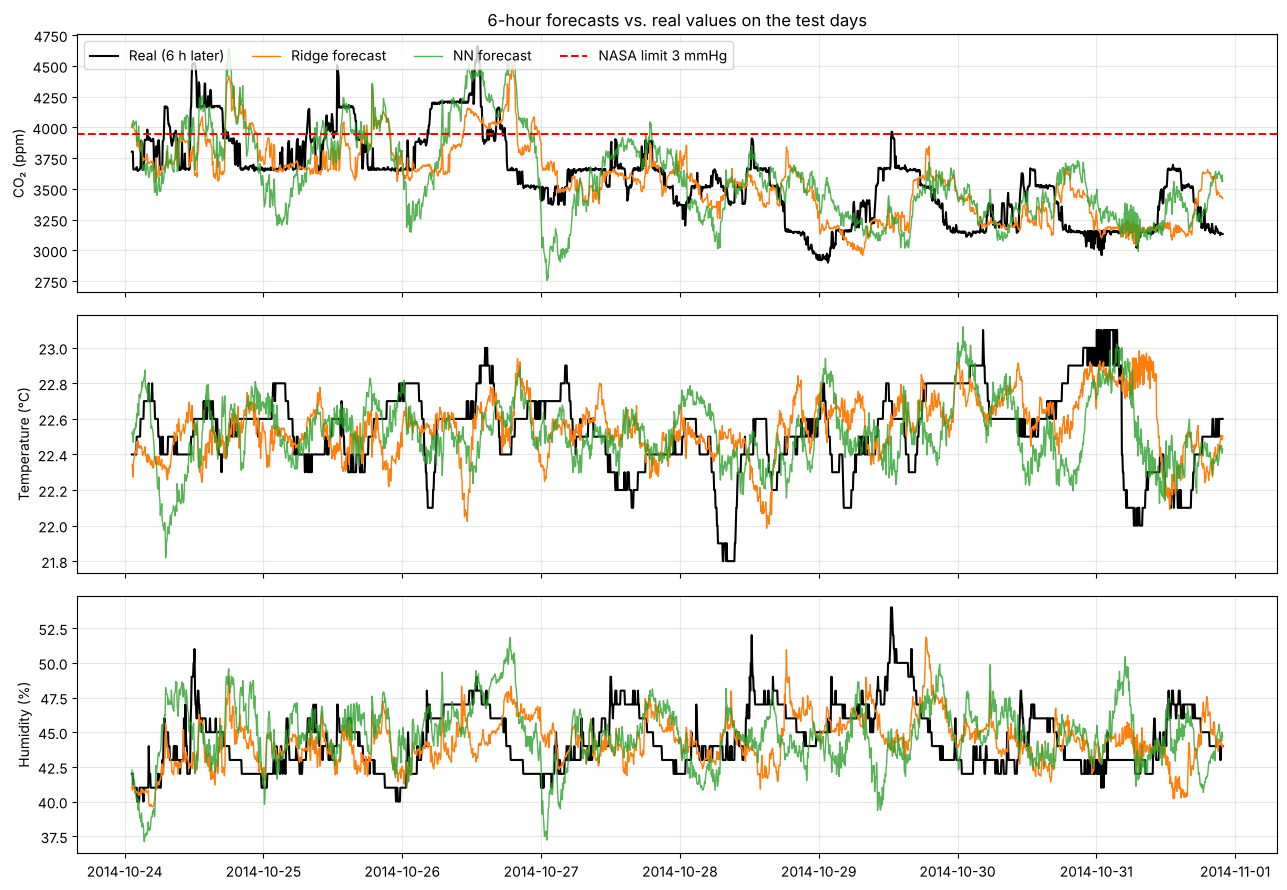

In [18]:
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

ridge = make_pipeline(StandardScaler(), Ridge()).fit(X_train, y_train).predict(X_test)   # scaled like the MLP; pred = NN predictions
t = df2["Controller_Time_GMT"].iloc[cut:].loc[y_test.index]   # time of each test row
names = ["CO₂ (ppm)", "Temperature (°C)", "Humidity (%)"]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(t, y_test.iloc[:, j], color="black", lw=1.5, label="Real (6 h later)")
    ax.plot(t, ridge[:, j], color="tab:orange", lw=1, label="Ridge forecast")
    ax.plot(t, pred[:, j], color="tab:green", lw=1, alpha=0.8, label="NN forecast")
    ax.set_ylabel(names[j]); ax.grid(alpha=0.3)
axes[0].axhline(3 * 1316, color="red", ls="--", label="NASA limit 3 mmHg")
axes[0].legend(loc="upper left", ncol=4)
axes[0].set_title("6-hour forecasts vs. real values on the test days")
plt.tight_layout(); plt.show()

# Section D: ISS radiation (NASA OSDR RadLab)

## Part 11: Dose-rate map and 24-hour dose forecast
The EDA only gives one radiation number per day. **RadLab** gives the detail: the absorbed dose rate measured by a dosimeter about every 100 seconds, with the station's latitude, longitude and altitude at that moment. We use the **DOSIS-3D DOSTEL-1** detector in the Columbus module, June–December 2014 (the RR-1 mission falls inside this period).

Why position matters: most of the dose that changes from day to day comes from passes through the **South Atlantic Anomaly (SAA)**, where the inner radiation belt dips closest to Earth. The station's orbit is known in advance, so if a model learns *dose rate as a function of position*, we can add up the predicted dose along tomorrow's ground track.

The cells below:
1. Download the DOSTEL-1 readings month by month from the RadLab API.
2. Check the unit (µGy/h) by comparing daily totals with the EDA's daily radiation for RR-1. The detector samples faster inside the SAA, so daily totals must be **time-weighted**; a plain average of the samples would count the SAA about twice.
3. Train a small neural network (same size as Part 9: one hidden layer of 32) to predict log dose rate from latitude, longitude and altitude. The first 80 % of the timeline trains, the last 20 % tests.
4. Judge the **24-hour dose forecast** against *persistence* ("the next 24 h equals the last 24 h").

In [19]:
import numpy as np
import pandas as pd
import requests
from io import StringIO

RADLAB_URL = "https://visualization.osdr.nasa.gov/radlab/api/"
INSTRUMENT = "DosTel1"

# 1. Download month by month (each request returns about 27,000 readings as CSV)
months = pd.date_range("2014-06-01", "2015-01-01", freq="MS")
parts = []
for start, end in zip(months[:-1], months[1:]):
    query = (f"?instrument={INSTRUMENT}&timestamp>={start:%Y-%m-%d}&timestamp<{end:%Y-%m-%d}"
             "&absorbed_dose_rate&latitude&longitude&altitude")
    r = requests.get(RADLAB_URL + query, timeout=300)
    r.raise_for_status()
    parts.append(pd.read_csv(StringIO(r.text)))

rad_df = pd.concat(parts, ignore_index=True)
rad_df["timestamp"] = pd.to_datetime(rad_df["timestamp"])
rad_df = (rad_df.drop_duplicates("timestamp").set_index("timestamp").sort_index()
          [["absorbed_dose_rate", "latitude", "longitude", "altitude"]].dropna())
print(f"Loaded {len(rad_df):,} DOSTEL-1 readings: {rad_df.index.min()} -> {rad_df.index.max()}")
print("Median time between readings:", rad_df.index.to_series().diff().median())


def to_grid(df: pd.DataFrame, freq: str = "1min") -> pd.DataFrame:
    """Time-interpolates the readings onto an even grid, so averages are time-weighted."""
    grid = pd.date_range(df.index.min().ceil(freq), df.index.max().floor(freq), freq=freq)
    both = df.index.union(grid)
    out = df[["absorbed_dose_rate", "latitude", "altitude"]].reindex(both).interpolate("time").reindex(grid)
    # Longitude jumps from +180 to -180: unwrap before interpolating, wrap again after
    lon = pd.Series(np.unwrap(np.deg2rad(df["longitude"].values)), index=df.index)
    out["longitude"] = (np.rad2deg(lon.reindex(both).interpolate("time").reindex(grid)) + 180) % 360 - 180
    return out


# 2. Unit check against the EDA's daily radiation for RR-1 (mGy/day)
rad_min = to_grid(rad_df)
daily_dostel = rad_min["absorbed_dose_rate"].resample("1h").mean().resample("1D").sum() / 1000   # µGy/h -> mGy/day

eda_rad = pd.DataFrame(requests.get(
    "https://visualization.osdr.nasa.gov/eda/api/missions/RR-1/radiation_data/", timeout=120).json())
eda_rad["time"] = pd.to_datetime(eda_rad["time"]).dt.tz_localize(None)
check = pd.concat([daily_dostel.rename("DOSTEL-1 (RadLab)"), eda_rad.set_index("time")["total"].rename("EDA total")],
                  axis=1).dropna()
print(f"\nDaily dose over the {len(check)} RR-1 days, mGy/day:")
print(check.describe().loc[["mean", "min", "max"]].round(3))
print(f"Mean ratio RadLab / EDA: {(check.iloc[:, 0] / check.iloc[:, 1]).mean():.2f}  (close to 1, so the unit is µGy/h)")
print(f"Plain sample mean x 24 h would give {rad_df['absorbed_dose_rate'].mean() * 24 / 1000:.2f} mGy/day: too high, "
      "because sampling is denser inside the SAA")

Loaded 192,373 DOSTEL-1 readings: 2014-06-01 00:00:20 -> 2014-12-31 23:59:40
Median time between readings: 0 days 00:01:40



Daily dose over the 39 RR-1 days, mGy/day:
      DOSTEL-1 (RadLab)  EDA total
mean              0.218      0.204
min               0.180      0.189
max               0.256      0.231
Mean ratio RadLab / EDA: 1.07  (close to 1, so the unit is µGy/h)
Plain sample mean x 24 h would give 0.60 mGy/day: too high, because sampling is denser inside the SAA


In [20]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

RAD_FEATURES = ["latitude", "sin_longitude", "cos_longitude", "altitude"]


def rad_inputs(df: pd.DataFrame) -> np.ndarray:
    """Position features. Longitude enters as sine and cosine so that -180 and +180 are neighbours."""
    lon = np.deg2rad(df["longitude"].values)
    return np.c_[df["latitude"].values, np.sin(lon), np.cos(lon), df["altitude"].values]


# 3. Chronological split: first 80 % of the timeline trains, last 20 % tests
rad_cut = rad_df.index[int(len(rad_df) * 0.8)]
rad_train, rad_test = rad_df[rad_df.index < rad_cut], rad_df[rad_df.index >= rad_cut]

rad_nn = make_pipeline(StandardScaler(),
                       MLPRegressor(hidden_layer_sizes=(32,), early_stopping=True,
                                    max_iter=300, random_state=0))
rad_nn.fit(rad_inputs(rad_train), np.log(rad_train["absorbed_dose_rate"].values))   # log: dose rate spans 1 to 600 µGy/h

rad_pred = np.exp(rad_nn.predict(rad_inputs(rad_test)))
print(f"Train: {len(rad_train):,} readings up to {rad_cut:%Y-%m-%d}   Test: {len(rad_test):,} readings after")
print(f"Dose-rate map on the test period: R² (log scale) = {r2_score(np.log(rad_test['absorbed_dose_rate']), np.log(rad_pred)):.3f}, "
      f"MAE = {mean_absolute_error(rad_test['absorbed_dose_rate'], rad_pred):.2f} µGy/h")

# 4. 24-hour dose forecast: add up the predicted dose rate along the next 24 h of the orbit
test_min = rad_min[rad_min.index >= rad_cut].copy()
test_min["predicted"] = np.exp(rad_nn.predict(rad_inputs(test_min)))
hourly = test_min[["absorbed_dose_rate", "predicted"]].resample("1h").mean()

rad_eval = pd.DataFrame({
    "actual": sum(hourly["absorbed_dose_rate"].shift(-k) for k in range(1, 25)) / 1000,       # mGy over the next 24 h
    "model": sum(hourly["predicted"].shift(-k) for k in range(1, 25)) / 1000,
    "persistence": sum(hourly["absorbed_dose_rate"].shift(k) for k in range(0, 24)) / 1000,   # mGy over the last 24 h
}).dropna()

rad_mae = mean_absolute_error(rad_eval["actual"], rad_eval["model"])
rad_base = mean_absolute_error(rad_eval["actual"], rad_eval["persistence"])
print(f"\n24-hour dose forecast on the test period ({len(rad_eval)} hourly start times), mGy:")
print(f"  Position model MAE: {rad_mae:.4f}   persistence baseline: {rad_base:.4f}   "
      f"({(1 - rad_mae / rad_base) * 100:.0f} % lower error)")

# Watch level for the app: the 95th percentile of 24-hour dose in the training period
train_hourly = rad_min.loc[rad_min.index < rad_cut, "absorbed_dose_rate"].resample("1h").mean()
train_24h = (sum(train_hourly.shift(k) for k in range(0, 24)) / 1000).dropna()
RAD_WATCH = float(train_24h.quantile(0.95))
print(f"  Typical 24-hour dose in training: {train_24h.median():.3f} mGy; 95th percentile (app watch level): {RAD_WATCH:.3f} mGy")

Train: 153,898 readings up to 2014-11-18   Test: 38,475 readings after
Dose-rate map on the test period: R² (log scale) = 0.957, MAE = 6.71 µGy/h

24-hour dose forecast on the test period (988 hourly start times), mGy:
  Position model MAE: 0.0064   persistence baseline: 0.0108   (41 % lower error)
  Typical 24-hour dose in training: 0.223 mGy; 95th percentile (app watch level): 0.247 mGy


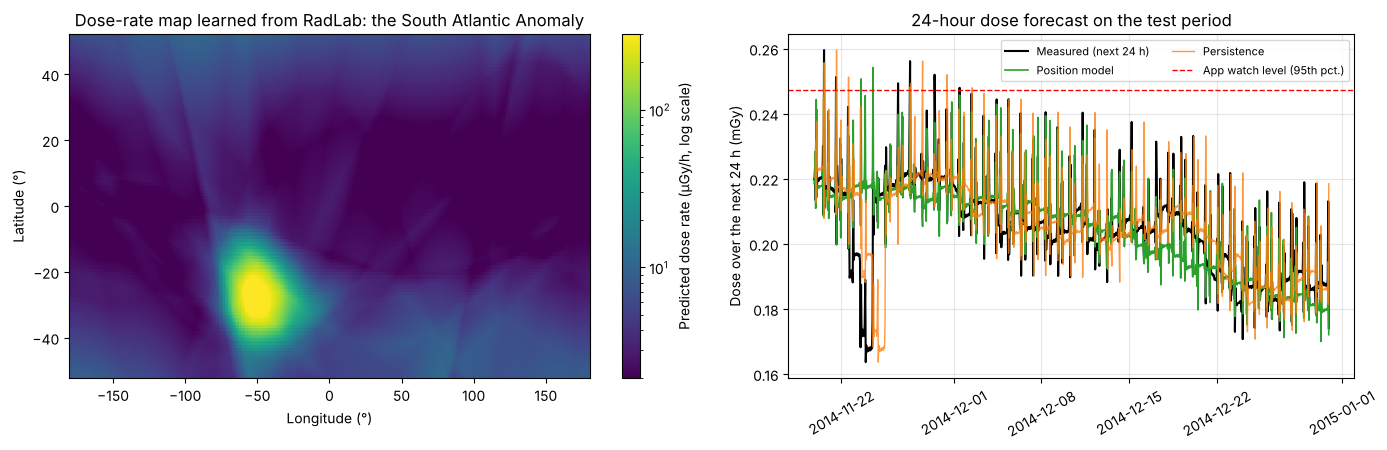

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

# Left: the dose-rate map the network learned, at the mean altitude
lat_grid, lon_grid = np.meshgrid(np.linspace(-51.6, 51.6, 104), np.linspace(-180, 180, 361), indexing="ij")
map_df = pd.DataFrame({"latitude": lat_grid.ravel(), "longitude": lon_grid.ravel(),
                       "altitude": rad_df["altitude"].mean()})
dose_map = np.exp(rad_nn.predict(rad_inputs(map_df))).reshape(lat_grid.shape)
im = axes[0].pcolormesh(lon_grid, lat_grid, dose_map, cmap="viridis",
                        norm=plt.matplotlib.colors.LogNorm(vmin=2, vmax=300), shading="auto")
fig.colorbar(im, ax=axes[0], label="Predicted dose rate (µGy/h, log scale)")
axes[0].set_xlabel("Longitude (°)"); axes[0].set_ylabel("Latitude (°)")
axes[0].set_title("Dose-rate map learned from RadLab: the South Atlantic Anomaly")

# Right: 24-hour dose forecast vs what was measured, test period
axes[1].plot(rad_eval.index, rad_eval["actual"], color="black", lw=1.5, label="Measured (next 24 h)")
axes[1].plot(rad_eval.index, rad_eval["model"], color="tab:green", lw=1.2, label="Position model")
axes[1].plot(rad_eval.index, rad_eval["persistence"], color="tab:orange", lw=1, alpha=0.8, label="Persistence")
axes[1].axhline(RAD_WATCH, color="red", ls="--", lw=1, label="App watch level (95th pct.)")
axes[1].set_ylabel("Dose over the next 24 h (mGy)"); axes[1].grid(alpha=0.3)
axes[1].set_title("24-hour dose forecast on the test period")
axes[1].legend(fontsize=8, ncol=2); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# Section E: Link to the Space Fog app

## Part 12: Export the trained models
The app runs in a browser, so it cannot load scikit-learn objects. This cell writes everything the app needs to one JSON file, `space_fog_models.json`, and the app repeats the same arithmetic in JavaScript:

| Model | Trained in | What is exported | What the app does with it |
|---|---|---|---|
| Cabin forecaster (MLP) | Part 9, NASA EDA | Input and label scalers, the two weight matrices | Every risk prediction: forecasts CO₂, temperature and humidity 6 h ahead and compares them with the NASA limits |
| Radiation map (MLP) | Part 11, NASA RadLab | Input scaler, the two weight matrices, the watch level | Adds up predicted dose along the next 24 h of the orbit |
| Physiological strain (Random Forest) | Part 5, PhysioNet | All 200 trees (split feature, threshold, children, leaf probability) | Turns the wearable's four z-scores into the strain score used in the Part 6 fusion |

It also exports the **held-out test periods** on a 5-minute grid: the cabin telemetry, and the DOSTEL-1 dose rate with the station's position. The app replays these as its "live" sensors, so the models always forecast data they were not trained on. For the radiation forecast the app reads the next 24 h of positions from the replay (the orbit is known in advance), interpolates them to 1-minute steps and adds up the model's dose rate; it never reads the future dose.

The last lines re-compute a few predictions from the exported numbers alone and compare them with scikit-learn, to prove the export is exact.

In [22]:
import json
import joblib

# ---- Cabin forecaster (Part 9) ----
cabin_scaler, cabin_mlp = nn.named_steps["standardscaler"], nn.named_steps["mlpregressor"]
cabin_replay = df2.iloc[cut:]                               # the held-out last 20 % of RR-1
cabin_metrics = {}
for j, c in enumerate(FEATURES):
    cabin_metrics[c] = {"mlp_mae": round(float(mean_absolute_error(y_test.iloc[:, j], pred[:, j])), 3),
                        "persistence_mae": round(float(mean_absolute_error(y_test.iloc[:, j], X_test[f"{c}_t-0min"])), 3)}

cabin_export = {
    "source": "NASA OSDR Environmental Data Application API, mission RR-1",
    "train_period": [str(df2["Controller_Time_GMT"].iloc[0]), str(df2["Controller_Time_GMT"].iloc[cut - 1])],
    "test_period": [str(cabin_replay["Controller_Time_GMT"].iloc[0]), str(cabin_replay["Controller_Time_GMT"].iloc[-1])],
    "features": FEATURES, "W": W, "STEP": STEP, "H": H, "ppm_per_mmHg": 1316,
    "x_mean": cabin_scaler.mean_.round(5).tolist(), "x_scale": cabin_scaler.scale_.round(5).tolist(),
    "y_mean": y_scaler.mean_.round(5).tolist(), "y_scale": y_scaler.scale_.round(5).tolist(),
    "W1": cabin_mlp.coefs_[0].round(6).tolist(), "b1": cabin_mlp.intercepts_[0].round(6).tolist(),
    "W2": cabin_mlp.coefs_[1].round(6).tolist(), "b2": cabin_mlp.intercepts_[1].round(6).tolist(),
    "metrics": cabin_metrics,
    "replay": {"co2_ppm": cabin_replay["CO2_ppm_ISS"].round(0).astype(int).tolist(),
               "temp_c": cabin_replay["Temp_degC_ISS"].round(2).tolist(),
               "rh_pct": cabin_replay["RH_percent_ISS"].round(1).tolist()},
}

# ---- Radiation map (Part 11) ----
rad_scaler, rad_mlp = rad_nn.named_steps["standardscaler"], rad_nn.named_steps["mlpregressor"]
rad_test_min = to_grid(rad_test, "1min")
rad_replay = pd.concat([
    rad_test_min["absorbed_dose_rate"].resample("5min").mean(),                  # measured dose rate: 5-minute mean
    rad_test_min[["latitude", "longitude", "altitude"]].resample("5min").first(),  # position at the start of each step
], axis=1).iloc[:len(cabin_replay)]                                              # same number of steps as the cabin replay
rad_export = {
    "source": "NASA OSDR RadLab API, DOSIS-3D DOSTEL-1 (ISS Columbus)",
    "train_period": [str(rad_train.index[0]), str(rad_train.index[-1])],
    "test_period": [str(rad_test.index[0]), str(rad_test.index[-1])],
    "features": RAD_FEATURES, "target": "log absorbed dose rate (µGy/h)",
    "x_mean": rad_scaler.mean_.round(5).tolist(), "x_scale": rad_scaler.scale_.round(5).tolist(),
    "W1": rad_mlp.coefs_[0].round(6).tolist(), "b1": rad_mlp.intercepts_[0].round(6).tolist(),
    "W2": rad_mlp.coefs_[1].round(6).ravel().tolist(), "b2": round(float(rad_mlp.intercepts_[1][0]), 6),
    "watch_24h_mGy": round(RAD_WATCH, 4), "median_24h_mGy": round(float(train_24h.median()), 4),
    "metrics": {"forecast_24h_mae_mGy": round(float(rad_mae), 4), "persistence_mae_mGy": round(float(rad_base), 4),
                "map_r2_log": round(float(r2_score(np.log(rad_test["absorbed_dose_rate"]), np.log(rad_pred))), 3)},
    "replay": {"dose_uGy_h": rad_replay["absorbed_dose_rate"].round(2).tolist(),
               "lat": rad_replay["latitude"].round(2).tolist(),
               "lon": rad_replay["longitude"].round(2).tolist(),
               "alt": rad_replay["altitude"].round(1).tolist()},
}

# ---- Physiological strain forest (Part 5) ----
try:
    phys_model, phys_features = final_model, feature_cols
except NameError:                                           # Section A not run in this session
    saved = joblib.load("space_fog_phys_model.joblib")
    phys_model, phys_features = saved["model"], saved["features"]

trees = []
for est in phys_model.estimators_:
    t = est.tree_
    leaf_prob = t.value[:, 0, 1] / t.value[:, 0, :].sum(axis=1)             # share of "abnormal" in each node
    trees.append({"f": t.feature.tolist(),                                  # split feature (-2 = leaf)
                  "t": np.round(t.threshold, 4).tolist(),
                  "l": t.children_left.tolist(), "r": t.children_right.tolist(),
                  "p": np.round(leaf_prob, 4).tolist()})
phys_export = {
    "source": "PhysioNet respiratory & heart-rate dataset, 20 subjects",
    "features": phys_features, "sd_floors": SD_FLOORS, "trees": trees,
    "metrics": {"rule_reproduction_auc": round(float(roc_auc_score(y, oof_probs)), 3),
                "fem_vs_peep_auc": round(float(roc_auc_score(y_maneuver, pair["oof_prob"])), 3)},
}

with open("space_fog_models.json", "w") as f:
    json.dump({"cabin": cabin_export, "rad": rad_export, "phys": phys_export}, f, separators=(",", ":"))
import os
print(f"Wrote space_fog_models.json ({os.path.getsize('space_fog_models.json') / 1024:.0f} kB)")


# ---- Proof that the export is exact: redo the predictions from the exported numbers only ----
def mlp_from_export(x, m):
    hidden = np.maximum(0, ((x - np.array(m["x_mean"])) / np.array(m["x_scale"])) @ np.array(m["W1"]) + np.array(m["b1"]))
    return hidden @ np.array(m["W2"]) + np.array(m["b2"])

x0 = X_test.iloc[:200].values
cabin_js = mlp_from_export(x0, cabin_export) * np.array(cabin_export["y_scale"]) + np.array(cabin_export["y_mean"])
print("Cabin MLP, largest difference from scikit-learn:", float(np.abs(cabin_js - pred[:200]).max().round(4)))

r0 = rad_inputs(rad_test.iloc[:200])
print("Radiation MLP, largest difference (µGy/h):",
      float(np.abs(np.exp(mlp_from_export(r0, rad_export)) - np.exp(rad_nn.predict(r0))).max().round(4)))

def forest_from_export(z):
    total = 0.0
    for tr in trees:
        node = 0
        while tr["f"][node] >= 0:
            node = tr["l"][node] if z[tr["f"][node]] <= tr["t"][node] else tr["r"][node]
        total += tr["p"][node]
    return total / len(trees)

z0 = X.iloc[:200].values
forest_js = np.array([forest_from_export(z) for z in z0])
print("Strain forest, largest difference from scikit-learn:",
      float(np.abs(forest_js - phys_model.predict_proba(X.iloc[:200])[:, 1]).max().round(4)))

Wrote space_fog_models.json (193 kB)
Cabin MLP, largest difference from scikit-learn: 0.0061
Radiation MLP, largest difference (µGy/h): 0.0038
Strain forest, largest difference from scikit-learn: 0.0
